# 04 - Phân tích không gian & xuất dữ liệu cho ArcGIS (ArcMap 10.4.1) / Power BI

**Input:** `data/processed/redd_predictions_for_gis.csv` (output của `03_modeling.ipynb`)

**Mục tiêu:**
1. Kiểm định **tự tương quan không gian** của mức ưu tiên bằng **Global Moran's I** (riêng từng tỉnh).
2. Kiểm tra **phần dư của mô hình** có còn cấu trúc không gian không (mô hình có bỏ sót yếu tố vị trí?).
3. Tìm **vùng nóng / vùng lạnh** (hot/cold spot) ưu tiên cao bằng **Getis-Ord Gi\***, so sánh vùng nóng thực tế và vùng nóng dự đoán.
4. Tổng hợp theo **tiểu khu** để xếp hạng đơn vị quản lý cần ưu tiên.
5. Xuất **ESRI Shapefile** (WGS84, tách theo tỉnh + lớp tổng hợp tiểu khu) mở trực tiếp trong **ArcMap 10.4.1** và **CSV** cho Power BI.

Các hàm thống kê không gian và xuất Shapefile nằm trong `src/spatial_utils.py` (chỉ dùng numpy/scipy và thư viện chuẩn Python).
Công thức giống PySAL/`esda` và công cụ *Spatial Statistics* của ArcGIS → có thể chạy lại trong ArcMap để đối chiếu.

**Ma trận trọng số:** K láng giềng gần nhất (KNN, k = 8) trên toạ độ chiếu (km), tính **riêng từng tỉnh** (2 tỉnh cách nhau ~800 km).

## 1. Thiết lập & đọc dữ liệu

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.spatial_utils import (project_xy_km, knn_weights, morans_i, getis_ord_gi_star,
                               classify_hotspot, gi_bin, to_shapefile)

FIG_DIR = ROOT / "outputs" / "figures"
TABLE_DIR = ROOT / "outputs" / "tables"
GIS_DIR = ROOT / "outputs" / "gis"
PBI_DIR = ROOT / "outputs" / "powerbi"
for d in (FIG_DIR, TABLE_DIR, GIS_DIR, PBI_DIR):
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False})
K = 8
PROVINCES = ["Nghe An", "Lam Dong"]

df = pd.read_csv(ROOT / "data" / "processed" / "redd_predictions_for_gis.csv")
df["is_high"] = (df["priority"] == "High").astype(int)
df["pred_high"] = (df["predicted_priority"] == "High").astype(int)
df["resid_high"] = df["is_high"] - df["prob_high"]          # phần dư xác suất của lớp High
print(f"{len(df):,} điểm")
df.groupby("province")[["is_high", "prob_high", "is_correct"]].mean().round(3)

18,851 điểm


,is_high,prob_high,is_correct
province,,,
Lam Dong,0.393,0.601,0.506
Nghe An,0.077,0.154,0.862


## 2. Global Moran's I

- **I > 0** và p < 0,05: các điểm có giá trị giống nhau có xu hướng **nằm gần nhau** (phân bố cụm).
- **I ≈ E[I] ≈ 0**: phân bố ngẫu nhiên trong không gian.
- p-value tính bằng **999 hoán vị** (permutation test), không cần giả định phân phối chuẩn.

Kiểm định trên 3 biến: nhãn High thực tế, xác suất High dự đoán, và **phần dư** (`is_high − prob_high`).

In [2]:
moran_rows = []
W_cache, XY_cache = {}, {}
for prov in PROVINCES:
    sub = df[df["province"] == prov]
    xy = project_xy_km(sub["latitude"], sub["longitude"])
    W = knn_weights(xy, k=K)
    XY_cache[prov], W_cache[prov] = xy, W
    for var, label in [("is_high", "Nhãn High thực tế"), ("prob_high", "Xác suất High dự đoán"),
                       ("resid_high", "Phần dư (thực tế − dự đoán)")]:
        r = morans_i(sub[var].values, W, permutations=999)
        moran_rows.append({"Tỉnh": prov, "Biến": label, "n": r["n"], "Moran's I": r["I"],
                           "E[I]": r["E[I]"], "z (hoán vị)": r["z_sim"], "p (hoán vị)": r["p_sim"]})

moran_df = pd.DataFrame(moran_rows).round(4)
moran_df.to_csv(TABLE_DIR / "spatial_morans_i.csv", index=False, encoding="utf-8-sig")
moran_df

,Tỉnh,Biến,n,Moran's I,E[I],z (hoán vị),p (hoán vị)
0,Nghe An,Nhãn High thực tế,13461,0.1167,-0.0001,28.6756,0.001
1,Nghe An,Xác suất High dự đoán,13461,0.5980,-0.0001,144.1883,0.001
2,Nghe An,Phần dư (thực tế − dự đoán),13461,0.1017,-0.0001,26.0400,0.001
3,Lam Dong,Nhãn High thực tế,5390,0.0927,-0.0002,14.6768,0.001
4,Lam Dong,Xác suất High dự đoán,5390,0.6406,-0.0002,98.4372,0.001
5,Lam Dong,Phần dư (thực tế − dự đoán),5390,0.0434,-0.0002,6.8722,0.001


__MORAN_MD__

## 3. Hot spot analysis — Getis-Ord Gi\*

Gi\* so sánh tổng giá trị của mỗi điểm + 8 láng giềng với trung bình toàn tỉnh. `Gi_Bin` từ −3 đến +3 tương ứng
cold/hot spot ở độ tin cậy 99/95/90% — **giống hệt trường `Gi_Bin` của công cụ *Hot Spot Analysis* trong ArcGIS (ArcMap 10.4.1 / ArcGIS Pro)**.

In [3]:
df["gi_z_actual"] = np.nan
df["gi_z_pred"] = np.nan
for prov in PROVINCES:
    m = (df["province"] == prov).values
    df.loc[m, "gi_z_actual"] = getis_ord_gi_star(df.loc[m, "is_high"].values, XY_cache[prov], k=K)
    df.loc[m, "gi_z_pred"] = getis_ord_gi_star(df.loc[m, "prob_high"].values, XY_cache[prov], k=K)

df["gi_bin_actual"] = gi_bin(df["gi_z_actual"].values)
df["gi_bin_pred"] = gi_bin(df["gi_z_pred"].values)
df["hotspot_actual"] = classify_hotspot(df["gi_z_actual"].values)
df["hotspot_pred"] = classify_hotspot(df["gi_z_pred"].values)

hs_order = ["Hot spot 99%", "Hot spot 95%", "Hot spot 90%", "Not significant",
            "Cold spot 90%", "Cold spot 95%", "Cold spot 99%"]
hs_tab = pd.crosstab(df["hotspot_actual"], df["province"]).reindex(hs_order).fillna(0).astype(int)
hs_tab.to_csv(TABLE_DIR / "spatial_hotspot_counts.csv", encoding="utf-8-sig")
hs_tab

province,Lam Dong,Nghe An
hotspot_actual,,
Hot spot 99%,82,1114
Hot spot 95%,244,0
Hot spot 90%,570,0
Not significant,3628,12347
Cold spot 90%,471,0
Cold spot 95%,395,0
Cold spot 99%,0,0


In [4]:
# Mức độ trùng khớp giữa vùng nóng THỰC TẾ và vùng nóng DỰ ĐOÁN (gộp về 3 lớp, mức tin cậy ≥ 95%)
def simplify(b):
    return np.select([b >= 2, b <= -2], ["Hot (≥95%)", "Cold (≥95%)"], "Không có ý nghĩa")

agree = pd.crosstab(simplify(df["gi_bin_actual"]), simplify(df["gi_bin_pred"]),
                    rownames=["Thực tế"], colnames=["Dự đoán"])
display(agree)
hot_a = df["gi_bin_actual"] >= 2
hot_p = df["gi_bin_pred"] >= 2
print(f"Tỷ lệ điểm hot spot thực tế cũng là hot spot dự đoán: {(hot_a & hot_p).sum() / hot_a.sum():.1%}")
print(f"Tỷ lệ điểm hot spot dự đoán đúng là hot spot thực tế : {(hot_a & hot_p).sum() / hot_p.sum():.1%}")

Dự đoán,Cold (≥95%),Hot (≥95%),Không có ý nghĩa
Thực tế,,,
Cold (≥95%),354,0,41
Hot (≥95%),0,857,583
Không có ý nghĩa,5452,2484,9080


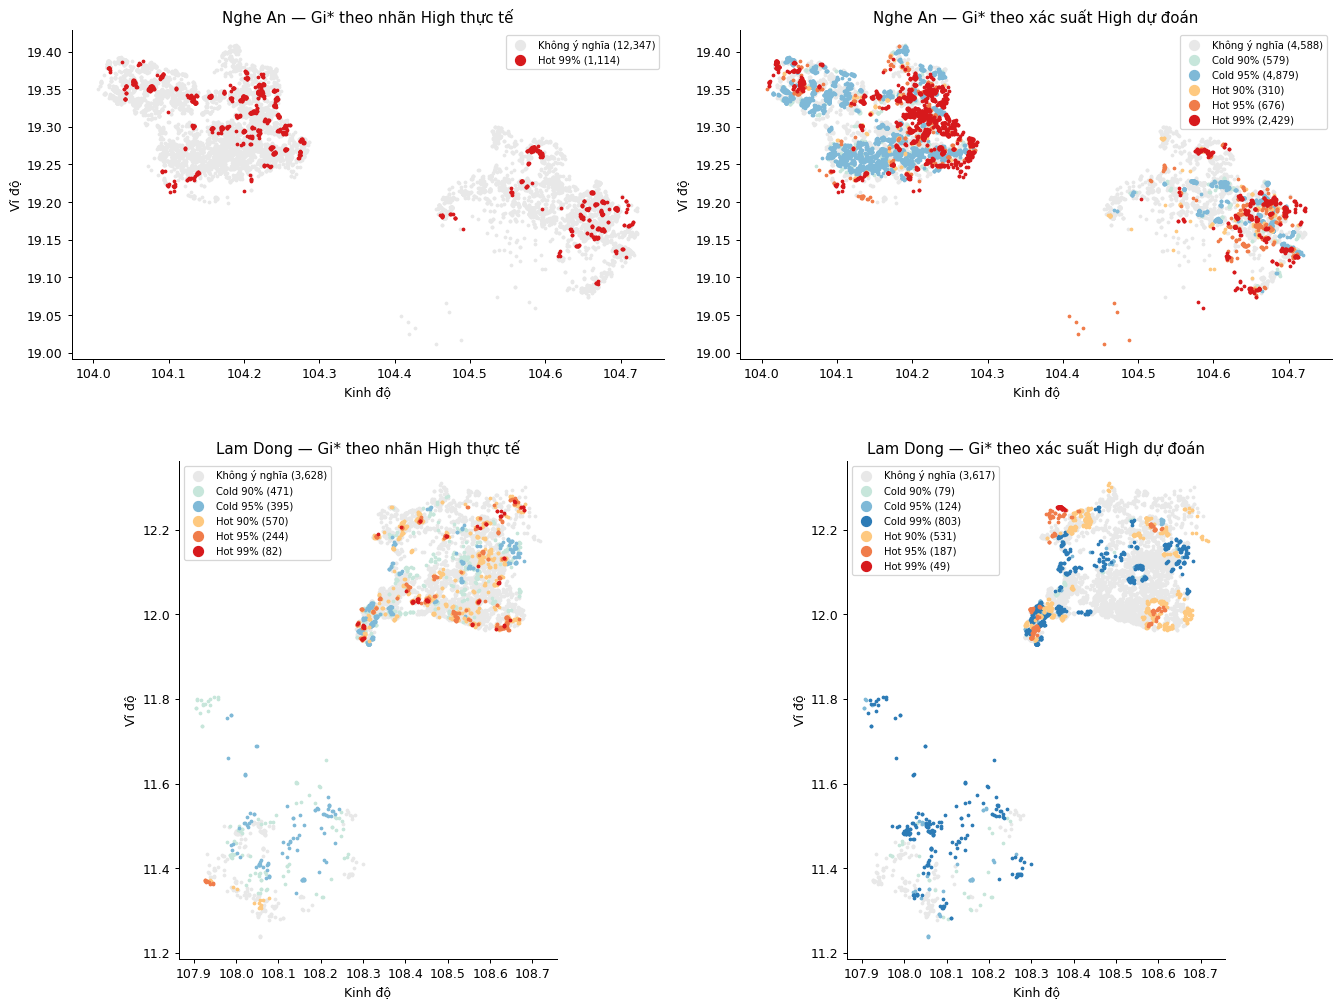

In [5]:
HS_COLORS = {3: "#d7191c", 2: "#f07c4a", 1: "#fec980", 0: "#e8e8e8", -1: "#c7e6db", -2: "#7fb9d7", -3: "#2c7bb6"}
HS_LABELS = {3: "Hot 99%", 2: "Hot 95%", 1: "Hot 90%", 0: "Không ý nghĩa", -1: "Cold 90%", -2: "Cold 95%", -3: "Cold 99%"}

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for row, prov in enumerate(PROVINCES):
    sub = df[df["province"] == prov]
    for col, (field, title) in enumerate([("gi_bin_actual", "nhãn High thực tế"), ("gi_bin_pred", "xác suất High dự đoán")]):
        ax = axes[row, col]
        for b in [0, -1, -2, -3, 1, 2, 3]:          # vẽ điểm có ý nghĩa sau cùng
            s = sub[sub[field] == b]
            if len(s):
                ax.scatter(s["longitude"], s["latitude"], s=4, c=HS_COLORS[b], label=f"{HS_LABELS[b]} ({len(s):,})")
        ax.set_title(f"{prov} — Gi* theo {title}"); ax.set_aspect("equal")
        ax.set_xlabel("Kinh độ"); ax.set_ylabel("Vĩ độ")
        ax.legend(markerscale=4, fontsize=8, loc="best")
plt.tight_layout(); plt.savefig(FIG_DIR / "spatial_hotspots_gi.png", bbox_inches="tight"); plt.show()

__HOTSPOT_MD__

## 4. Tổng hợp & xếp hạng theo tiểu khu

Tiểu khu là đơn vị quản lý thực tế → tổng hợp chỉ số cho từng tiểu khu, dùng toạ độ trung bình của các điểm làm vị trí đại diện.
`priority_index` = trung bình `prob_high` (xác suất ưu tiên cao do mô hình ước lượng); chỉ xếp hạng các tiểu khu có ≥ 10 điểm.

In [6]:
sz = (df.groupby(["province", "district", "spatial_group", "sub_region"])
        .agg(latitude=("latitude", "mean"), longitude=("longitude", "mean"),
             n_points=("id", "size"),
             share_natural=("forest_origin", lambda s: (s == "Natural forest").mean()),
             share_high_actual=("is_high", "mean"),
             priority_index=("prob_high", "mean"),
             accuracy=("is_correct", "mean"),
             share_hotspot=("gi_bin_actual", lambda b: (b >= 2).mean()),
             main_land_cover=("land_cover_group", lambda s: s.value_counts().index[0]))
        .reset_index())
sz["reliable"] = sz["n_points"] >= 10
sz["rank_in_province"] = (sz.where(sz["reliable"]).groupby("province")["priority_index"]
                            .rank(ascending=False, method="min"))
num_cols = ["share_natural", "share_high_actual", "priority_index", "accuracy", "share_hotspot"]
sz[num_cols] = sz[num_cols].round(4)
sz.to_csv(TABLE_DIR / "subzone_summary.csv", index=False, encoding="utf-8-sig")

print("Tương quan giữa priority_index (dự đoán) và tỷ lệ High thực tế theo tiểu khu (≥10 điểm):",
      round(sz.loc[sz["reliable"], ["priority_index", "share_high_actual"]].corr().iloc[0, 1], 3))
for prov in PROVINCES:
    print(f"\nTop 10 tiểu khu ưu tiên cao — {prov}")
    display(sz[(sz["province"] == prov) & sz["reliable"]].nsmallest(10, "rank_in_province")
              [["spatial_group", "district", "n_points", "share_natural", "share_high_actual", "priority_index",
                "share_hotspot", "main_land_cover"]])

Tương quan giữa priority_index (dự đoán) và tỷ lệ High thực tế theo tiểu khu (≥10 điểm): 0.831

Top 10 tiểu khu ưu tiên cao — Nghe An


,spatial_group,district,n_points,share_natural,share_high_actual,priority_index,share_hotspot,main_land_cover
224,NgheAn_463,Ky Son,45,1.0000,0.2222,0.4319,0.2889,Mixed
230,NgheAn_470,Ky Son,13,1.0000,0.1538,0.4222,0.0000,Mixed
225,NgheAn_464,Ky Son,315,0.9016,0.1460,0.3923,0.1333,Mixed
228,NgheAn_467,Ky Son,211,0.9052,0.1611,0.3795,0.1801,Mixed
223,NgheAn_462,Ky Son,384,0.6771,0.1589,0.2974,0.1745,Mixed
284,NgheAn_686,Tuong Duong,54,0.9444,0.1296,0.2890,0.0000,Evergreen broadleaf
212,NgheAn_449,Ky Son,73,0.6438,0.1644,0.2817,0.2877,Mixed
285,NgheAn_687,Tuong Duong,66,0.8333,0.1212,0.2721,0.1515,Evergreen broadleaf
277,NgheAn_674,Tuong Duong,131,0.7939,0.1145,0.2645,0.0916,Evergreen broadleaf
221,NgheAn_460,Ky Son,191,0.7435,0.1990,0.2622,0.2984,Mixed


,spatial_group,district,n_points,share_natural,share_high_actual,priority_index,share_hotspot,main_land_cover
149,LamDong_31,Lac Duong,15,1.0000,0.4667,0.7951,0.0000,Mixed
148,LamDong_30,Lac Duong,68,0.9853,0.4265,0.7866,0.0000,Mixed
122,LamDong_135,Lac Duong,33,1.0000,0.4545,0.7592,0.0000,Coniferous
125,LamDong_138,Lac Duong,33,1.0000,0.5152,0.7349,0.0303,Coniferous
123,LamDong_136,Lac Duong,20,1.0000,0.3000,0.7286,0.1000,Coniferous
127,LamDong_140,Lac Duong,42,1.0000,0.5238,0.7272,0.3095,Coniferous
120,LamDong_133,Lac Duong,24,1.0000,0.3750,0.7251,0.0000,Coniferous
154,LamDong_43,Lac Duong,11,1.0000,0.3636,0.7230,0.0000,Mixed
147,LamDong_28,Lac Duong,100,0.9800,0.5700,0.7224,0.1300,Mixed
116,LamDong_129,Lac Duong,11,1.0000,0.4545,0.7218,0.0000,Coniferous


## 5. Xuất dữ liệu cho ArcGIS & Power BI

In [7]:
point_cols = ["id", "latitude", "longitude", "province", "district", "commune", "sub_region", "spatial_group",
              "owner_type", "forest_origin", "land_cover_group", "stock_level", "land_type", "date", "year",
              "status", "low_precision_coord", "priority", "predicted_priority", "prob_high", "prob_medium",
              "prob_low", "confidence", "priority_rank_high", "is_correct", "error_type", "resid_high",
              "gi_z_actual", "gi_bin_actual", "hotspot_actual", "gi_z_pred", "gi_bin_pred", "hotspot_pred"]
points = df[point_cols].copy()
points[["resid_high", "gi_z_actual", "gi_z_pred"]] = points[["resid_high", "gi_z_actual", "gi_z_pred"]].round(4)

# --- ArcMap 10.4.1: xuất ESRI Shapefile (WGS84, EPSG:4326) thay cho GeoJSON
# Chuẩn DBF của Shapefile giới hạn tên cột ≤ 10 ký tự → quy ước rút gọn thống nhất và lưu bảng đối chiếu.
POINT_FIELD_MAP = {
    "id": "id",
    "province": "province",
    "district": "district",
    "commune": "commune",
    "sub_region": "sub_region",
    "spatial_group": "sub_code",
    "owner_type": "owner_type",
    "forest_origin": "origin",
    "land_cover_group": "cover_grp",
    "stock_level": "stock_lvl",
    "land_type": "land_type",
    "date": "date",
    "year": "year",
    "status": "status",
    "low_precision_coord": "low_prec",
    "priority": "priority",
    "predicted_priority": "pred_prio",
    "prob_high": "prob_high",
    "prob_medium": "prob_med",
    "prob_low": "prob_low",
    "confidence": "confidence",
    "priority_rank_high": "rank_high",
    "is_correct": "is_correct",
    "error_type": "error_type",
    "resid_high": "resid_high",
    "gi_z_actual": "gi_z_act",
    "gi_bin_actual": "gi_bin_act",
    "hotspot_actual": "hot_act",
    "gi_z_pred": "gi_z_pred",
    "gi_bin_pred": "gi_bin_prd",
    "hotspot_pred": "hot_pred",
}

SUBZONE_FIELD_MAP = {
    "province": "province",
    "district": "district",
    "spatial_group": "sub_code",
    "sub_region": "sub_region",
    "n_points": "n_points",
    "share_natural": "shr_nat",
    "share_high_actual": "shr_high",
    "priority_index": "prio_idx",
    "accuracy": "accuracy",
    "share_hotspot": "shr_hot",
    "main_land_cover": "main_cover",
    "reliable": "reliable",
    "rank_in_province": "rank_prov",
}

# Tách 2 shapefile điểm theo tỉnh cho nhẹ máy & dễ chiếu sang múi VN-2000 riêng khi lên bản đồ ArcMap
mapping_rows = []
for prov in PROVINCES:
    layer_name = f"redd_points_{prov.replace(' ', '_').lower()}"
    sub_pts = points[points["province"] == prov].reset_index(drop=True)
    to_shapefile(sub_pts, GIS_DIR / f"{layer_name}.shp", field_map=POINT_FIELD_MAP)
    for orig, short in POINT_FIELD_MAP.items():
        mapping_rows.append({"shapefile": layer_name, "ten_cot_goc": orig, "ten_cot_trong_shapefile": short})

# Lớp tổng hợp 303 tiểu khu: ArcMap 10.4.1 không hỗ trợ NULL ở cột số Shapefile
# → gán rank_in_province = 0 cho tiểu khu < 10 điểm (reliable = 0) để tránh hiển thị lỗi ****.
sz_shp = sz.copy()
sz_shp["reliable"] = sz_shp["reliable"].astype(int)
sz_shp["rank_in_province"] = sz_shp["rank_in_province"].fillna(0).astype(int)
to_shapefile(sz_shp, GIS_DIR / "subzone_summary.shp", field_map=SUBZONE_FIELD_MAP)
for orig, short in SUBZONE_FIELD_MAP.items():
    mapping_rows.append({"shapefile": "subzone_summary", "ten_cot_goc": orig, "ten_cot_trong_shapefile": short})

pd.DataFrame(mapping_rows).to_csv(GIS_DIR / "doi_chieu_ten_cot.csv", index=False, encoding="utf-8-sig")

# --- Power BI: CSV có cột Latitude/Longitude (dùng visual Map / Azure Maps / ArcGIS for Power BI)
points.to_csv(PBI_DIR / "fact_points.csv", index=False, encoding="utf-8-sig")
sz.to_csv(PBI_DIR / "dim_subzone.csv", index=False, encoding="utf-8-sig")
for name in ["model_comparison_cv", "feature_ablation", "permutation_importance", "best_model_by_segment",
             "best_model_lift_high", "spatial_morans_i", "eda_summary_by_district"]:
    src = TABLE_DIR / f"{name}.csv"
    if src.exists():
        pd.read_csv(src).to_csv(PBI_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

print("=== Outputs GIS (ESRI Shapefile cho ArcMap 10.4.1) ===")
for f in sorted(GIS_DIR.iterdir()):
    if f.suffix in (".shp", ".csv"):
        print(f"{str(f.relative_to(ROOT)):55s} {f.stat().st_size / 1e6:6.2f} MB")
print("\n=== Outputs Power BI ===")
for f in sorted(PBI_DIR.iterdir()):
    print(f"{str(f.relative_to(ROOT)):55s} {f.stat().st_size / 1e6:6.2f} MB")

=== Outputs GIS (ESRI Shapefile cho ArcMap 10.4.1) ===
outputs\gis\doi_chieu_ten_cot.csv                         0.00 MB
outputs\gis\redd_points_lam_dong.shp                      0.15 MB
outputs\gis\redd_points_nghe_an.shp                       0.38 MB
outputs\gis\subzone_summary.shp                           0.01 MB

=== Outputs Power BI ===
outputs\powerbi\best_model_by_segment.csv                 0.00 MB
outputs\powerbi\best_model_lift_high.csv                  0.00 MB
outputs\powerbi\dim_subzone.csv                           0.04 MB
outputs\powerbi\eda_summary_by_district.csv               0.00 MB
outputs\powerbi\fact_points.csv                           6.00 MB
outputs\powerbi\feature_ablation.csv                      0.00 MB
outputs\powerbi\model_comparison_cv.csv                   0.00 MB
outputs\powerbi\permutation_importance.csv                0.00 MB
outputs\powerbi\spatial_morans_i.csv                      0.00 MB


### Hướng dẫn trực quan hoá

**ArcGIS Desktop (ArcMap 10.4.1)**
1. Nhấn **Add Data** để mở trực tiếp 3 lớp Shapefile (hệ toạ độ `GCS_WGS_1984`, EPSG:4326) trong `outputs/gis/`:
   - `redd_points_nghe_an.shp` (13.461 điểm — Kỳ Sơn, Tương Dương)
   - `redd_points_lam_dong.shp` (5.390 điểm — Lạc Dương, Di Linh)
   - `subzone_summary.shp` (303 tiểu khu — dùng chung cho cả 2 tỉnh, mã tiểu khu là `sub_code`)
   *(Tên cột rút gọn ≤ 10 ký tự theo chuẩn DBF; tra bảng đối chiếu tại `outputs/gis/doi_chieu_ten_cot.csv`.)*
2. **Bản đồ phân loại ưu tiên:** *Layer Properties → Symbology → Categories → Unique Values* theo `priority` (thực tế) và `pred_prio` (dự đoán) — màu: High `#d7191c`, Medium `#fdae61`, Low `#1a9641`.
3. **Bản đồ vùng nóng (Hot Spot):** *Unique Values* theo `gi_bin_act` / `hot_act` (thực tế) và `gi_bin_prd` / `hot_pred` (dự đoán) — hoặc chạy lại *ArcToolbox → Spatial Statistics Tools → Mapping Clusters → Hot Spot Analysis (Getis-Ord Gi\*)* với trường `prob_high` (Conceptualization = `K_NEAREST_NEIGHBORS`, `Number_of_Neighbors = 8`) để đối chiếu với kết quả notebook.
4. **Bản đồ phần dư & sai số dự đoán:** *Quantities → Graduated Colors* theo `resid_high` hoặc đặt *Definition Query* `"error_type" <> 'Correct'` để khoanh vùng điểm dự đoán lệch.
5. **Bản đồ xếp hạng tiểu khu (`subzone_summary.shp`):**
   - Đặt *Definition Query*: `"reliable" = 1` (lọc các tiểu khu ≥ 10 điểm; các tiểu khu < 10 điểm có `reliable = 0` và `rank_prov = 0` không xếp hạng).
   - Chọn *Graduated Symbols* kích thước theo `n_points`, màu theo `prio_idx` (chỉ số ưu tiên ML) hoặc `shr_high` (tỷ lệ High thực tế); dán nhãn bằng `sub_code` hoặc `rank_prov`.
6. **Hệ quy chiếu:** Nên dùng *Project* chiếu sang **VN-2000 / UTM Zone 48N** (Nghệ An) và **VN-2000 / UTM Zone 49N** (Lâm Đồng) khi đo khoảng cách/diện tích; dùng ranh giới hành chính **trước 07/2025** cho đúng thời điểm dữ liệu.

**Power BI**
1. *Get Data → Text/CSV*: `fact_points.csv`, `dim_subzone.csv` và các bảng kết quả mô hình trong `outputs/powerbi/`.
2. Quan hệ `fact_points[spatial_group]` (nhiều) → `dim_subzone[spatial_group]` (một).
3. Gợi ý trang báo cáo: (1) Tổng quan dữ liệu, (2) Bản đồ ưu tiên thực tế vs dự đoán, (3) Hiệu năng mô hình
   (`model_comparison_cv`, `feature_ablation`, `best_model_lift_high`), (4) Xếp hạng tiểu khu + slicer tỉnh/huyện/loại rừng.
4. Một số measure DAX:
   ```DAX
   So diem = COUNTROWS(fact_points)
   Ty le High = DIVIDE(CALCULATE([So diem], fact_points[priority] = "High"), [So diem])
   Do chinh xac = AVERAGE(fact_points[is_correct])
   Xac suat High TB = AVERAGE(fact_points[prob_high])
   ```

__CONCLUSION_MD__